# Setup

In [ ]:
# Setup for colab
# !git clone https://github.com/fastai/course22p2.git
# %cd course22p2
# !pip install -q fastcore einops datasets timm
# import sys
# sys.path.append('/content/course22p2')
# !pip install -q k-diffusion fastcore einops datasets timm
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install -q fastcore einops datasets timm k-diffusion
# !pip install -q torcheval fastcore einops datasets timm k-diffusion
# !pip install -q numpy==1.26.4 --force-reinstall

In [6]:
# Kaggle Setup
!git clone https://github.com/fastai/course22p2.git
!pip install -q numpy --upgrade          # upgrade numpy FIRST
!pip install -q fastcore einops datasets timm k-diffusion torcheval

fatal: destination path 'course22p2' already exists and is not an empty directory.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dctorch 0.1.2 requires numpy<2.0.0,>=1.22.3, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but

In [7]:
# Kaggle Setup
import sys
sys.path.append('/kaggle/working/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [8]:
import os
import shutil, timm, torch, random, datasets, math, fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import torchvision.transforms as T
import torchvision.transforms.functional as TF,torch.nn.functional as F

from torch.utils.data import DataLoader,default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn,tensor
from datasets import load_dataset
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy
from functools import partial
from torch.optim import lr_scheduler
from torch import optim
from torchvision.io import read_image,ImageReadMode

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *
from miniai.training import *

from fastprogress import progress_bar
from glob import glob

torch.set_printoptions(precision=5, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['figure.dpi'] = 70

In [9]:
path_data = Path('../Data')
path_data.mkdir(exist_ok=True)
path = path_data/'tiny-imagenet-200'

url = 'http://cs231n.stanford.edu/tiny-imagenet-200.zip'
if not path.exists():
    path_zip = fc.urlsave(url, path_data)
    shutil.unpack_archive(path_zip, path_data)

# Data Processing

In [10]:
bs = 512
xmean,xstd = (tensor([0.47565, 0.40303, 0.31555]), tensor([0.28858, 0.24402, 0.26615]))

In [11]:
tfms = nn.Sequential(T.Pad(8), T.RandomCrop(64), T.RandomHorizontalFlip())

pad by 8 (64×64→ 80×80), and then crop back to 64

In [12]:
class TinyDS:
    def __init__(self, path):
        self.path = Path(path)
        self.files = glob(str(path/'**/*.JPEG'), recursive=True)
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = read_image(self.files[i], mode=ImageReadMode.RGB)/255
        return tfms((img-xmean[:,None,None])/xstd[:,None,None])

class TfmDS:
    def __init__(self, ds, tfmx=fc.noop, tfmy=fc.noop): self.ds,self.tfmx,self.tfmy = ds,tfmx,tfmy
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        item = self.ds[i]
        return self.tfmx(item),self.tfmy(item)

def denorm(x): return (x*xstd[:,None,None]+xmean[:,None,None]).clamp(0,1)

In [13]:
def tfmx(x,erase=True):
  x = TF.resize(x, (32,32))[None] # shrink to 32×32 (destroy detail)
  x = F.interpolate(x, scale_factor=2) # # stretch back to 64×64 (blocky)
  if erase: x = rand_erase(x)
  return x[0]  # because we have added extra dim earlier bec F.interpolate requires 4D. [None] adds a fake batch dim

In [14]:
tds = TinyDS(path/'train')
vds = TinyDS(path/'val')

tfm_tds = TfmDS(tds, tfmx)
tfm_vds = TfmDS(vds, partial(tfmx, erase=False))

dls = DataLoaders(*get_dls(tfm_tds, tfm_vds, bs=bs, num_workers=2))

In [15]:
xb,yb = next(iter(dls.train))

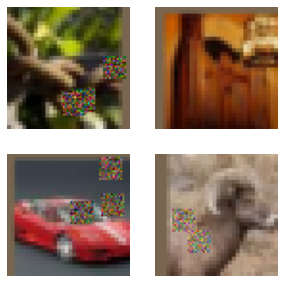

In [16]:
show_images(denorm(xb[:4]), imsize=2.5)

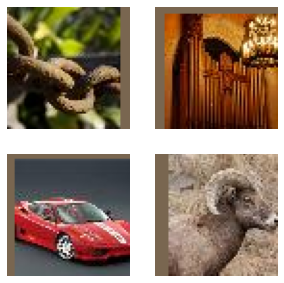

In [17]:
show_images(denorm(yb[:4]), imsize=2.5)

# Denoising AutoEncoder

In [18]:
def up_block(ni, nf, ks=3, act=act_gr, norm=None):
  return nn.Sequential(nn.UpsamplingNearest2d(scale_factor=2),
                       ResBlock(ni, nf, ks=ks, act=act, norm=norm))

    nn.UpsamplingNearest2d(scale_factor=2):
    before:  [[1, 2], after:  [[1, 1, 2, 2],
              [3, 4]]          [1, 1, 2, 2],
                               [3, 3, 4, 4],
                               [3, 3, 4, 4]]


In [19]:
def get_model(act=act_gr, nfs=(32,64,128,256,512,1024), norm=nn.BatchNorm2d, drop=0.1):
    layers = [ResBlock(3, nfs[0], ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)] #Down_sampling
    layers += [up_block(nfs[i], nfs[i-1], act=act, norm=norm) for i in range(len(nfs)-1,0,-1)] #Up_sampling
    layers += [ResBlock(nfs[0], 3, act=nn.Identity, norm=norm)] #Make final_features=3
    return nn.Sequential(*layers)

In [20]:
iw = partial(init_weights, leaky=0.1)

In [21]:
metrics = MetricsCB()
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), MixedPrecision()]
lr_cbs = [DeviceCB(), ProgressCB(), MixedPrecision()]
opt_func = partial(optim.AdamW, eps=1e-5)

/kaggle/working/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="29"></progress> 14.80% [29/196 00:20&lt;01:57... 1.510]</div></div>

/kaggle/working/course22p2/miniai/learner.py:229: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.sched.step()


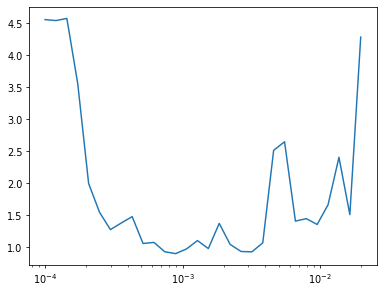

In [22]:
Learner(get_model().apply(iw), dls, F.mse_loss, cbs=lr_cbs, opt_func=opt_func).lr_find(start_lr=1e-4, gamma=1.2)

In [23]:
epochs = 5
lr = 1e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(get_model().apply(iw), dls, F.mse_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [24]:
# learn.fit(epochs)

    loss	epoch	train
    0.741	0	train
    0.394	0	eval
    0.343	1	train
    0.296	1	eval
    0.277	2	train
    0.247	2	eval
    0.249	3	train
    0.227	3	eval
    0.240	4	train
    0.224	4	eval

In [25]:
# preds,targs,inp = learn.capture_preds(inps=True)

In [26]:
# show_images(denorm(inp[:9]), imsize=2)

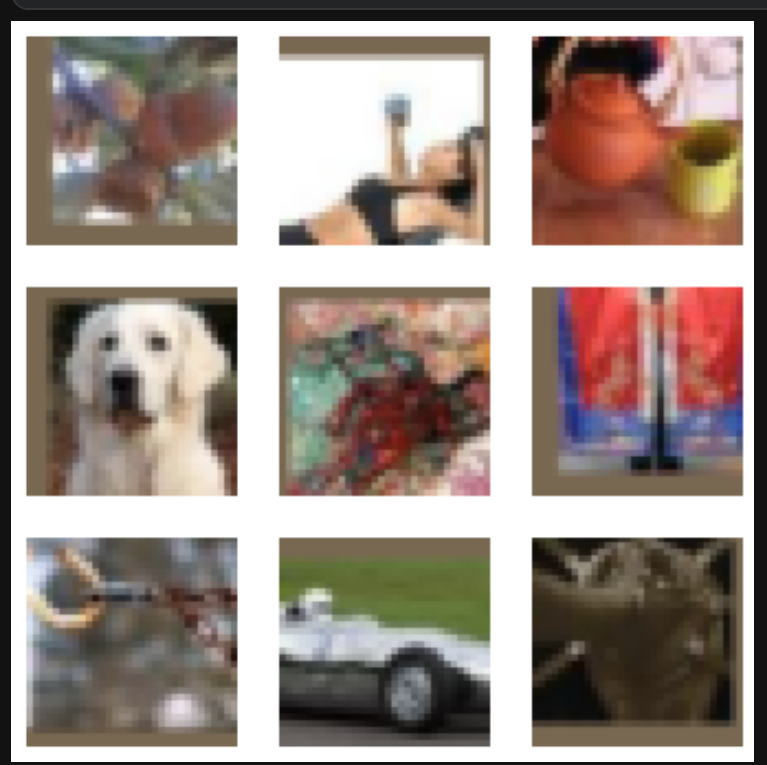


In [27]:
# show_images(denorm(preds[:9]), imsize=2)


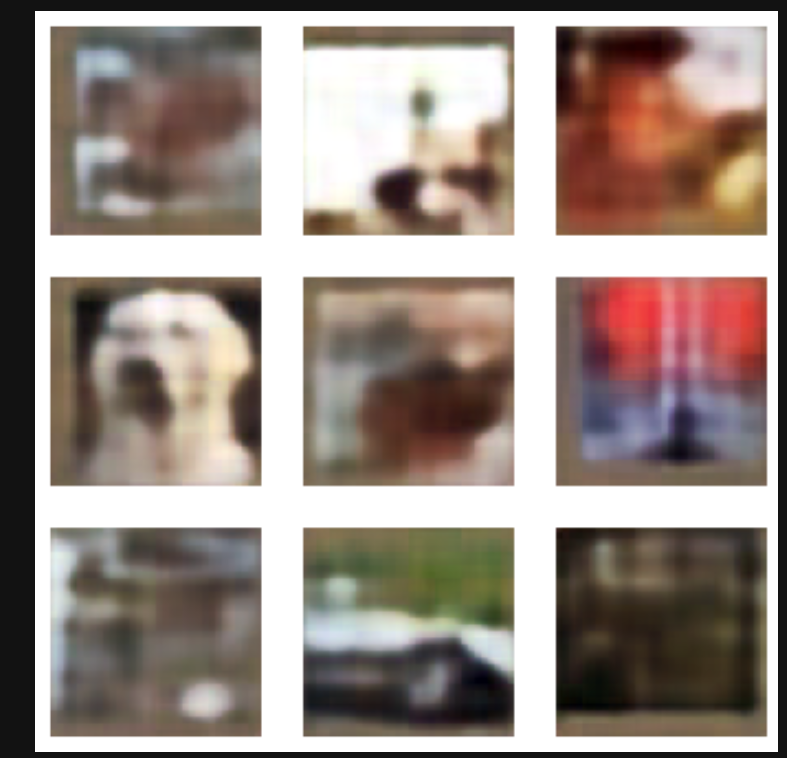

In [28]:
# show_images(denorm(targs[:9]), imsize=2)

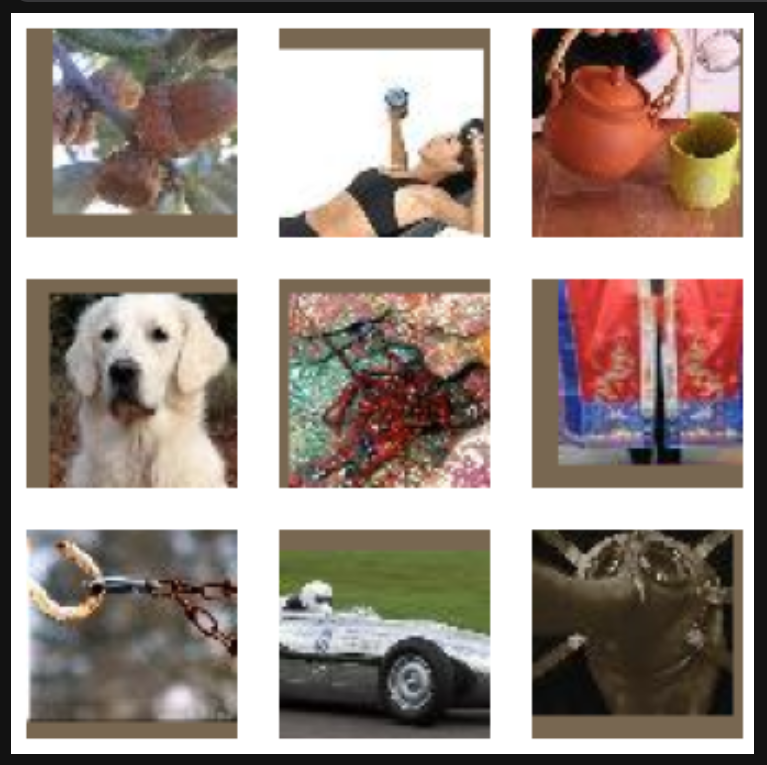

# Unet

In [29]:
# del(learn)
clean_mem()

In [30]:
class TinyUnet(nn.Module):
  def __init__(self, act=act_gr, nfs=(32,64,128,256,512,1024), norm=nn.BatchNorm2d):
    super().__init__()
    self.start = ResBlock(3, nfs[0], stride=1, act=act, norm=norm)
    self.dn = nn.ModuleList([ResBlock(nfs[i], nfs[i+1], stride=2, act=act, norm=norm) for i in range(len(nfs)-1)])
    self.up = nn.ModuleList([up_block(nfs[i], nfs[i-1], act=act, norm=norm) for i in reversed(range(1,len(nfs)))])
    self.up += [ResBlock(nfs[0], 3, stride=1, act=act, norm=norm)]
    self.end =  ResBlock(3, 3, act=nn.Identity, norm=norm)

  def forward(self, x):
    layers = [x]
    x = self.start(x)
    for l in self.dn:
      layers.append(x)
      x = l(x)
    n = len(layers)
    for i,l in enumerate(self.up):
      if i!=0: x += layers[n-i] # add equivelant in down_samp (can also concat)
      x = l(x)
    return  self.end(x+layers[0])

- `nn.Sequential` — fixed forward pass, input flows through every layer in order automatically. no control.
- `nn.ModuleList` — just a list of layers that PyTorch tracks. you manually control how and when to use them in forward() [We can loop through the layers]
- `act=nn.Identity` — means No activation, just like `fc.noop`

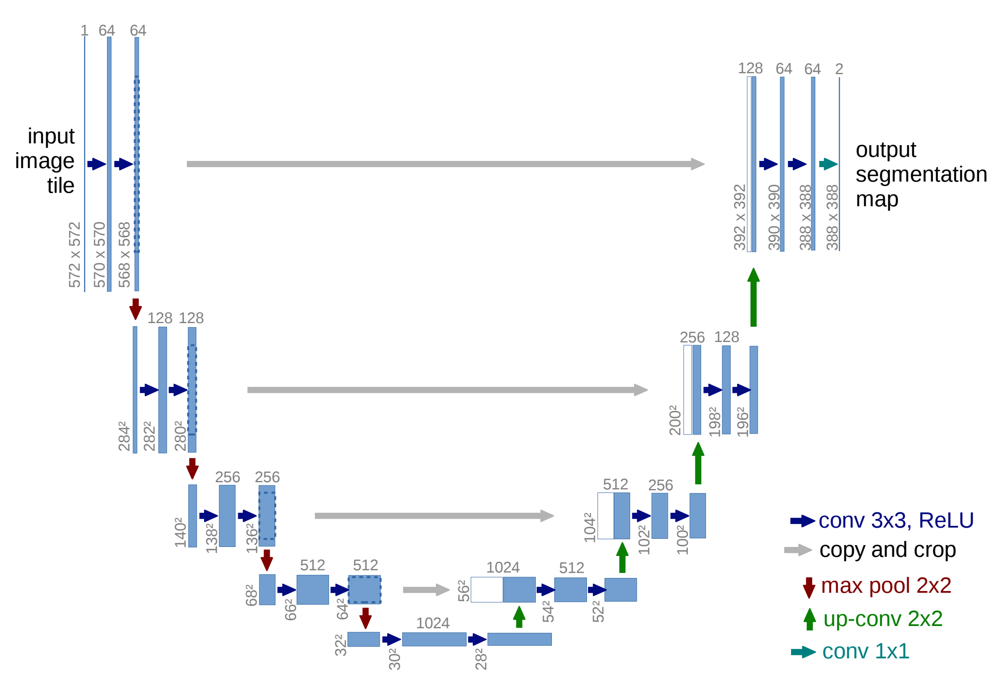

Our diff from the original:
- Using `ResNets` instead of just `Convs`
- Using `Addition` in the `Crop and copy skipping` arrows instead of `Concatenation`

In [31]:
def zero_weights(l):
  with torch.no_grad():
    l.weight.zero_()
    l.bias.zero_()

In [32]:
model = TinyUnet()

In [33]:
last_res = model.up[-1]
zero_weights(last_res.convs[-1][-1])
zero_weights(last_res.idconv[0])
zero_weights(model.end.convs[-1][-1])

Here we are Initializing (as zeros) -> [identity effect at start, `output = input`]:
 - `last Resnet` in up_sampling ->(`convs`, `id_conv`)
 - `Ending Resnet` -> `convs` only, leave the `id_conv`(output the input at the beginning)




<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="35"></progress> 17.86% [35/196 00:21&lt;01:41... 0.275]</div></div>

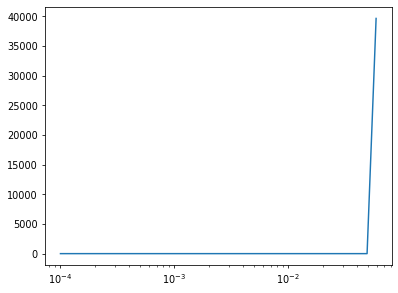

In [34]:
Learner(model, dls, F.mse_loss, cbs=lr_cbs, opt_func=opt_func).lr_find(start_lr=1e-4, gamma=1.2)

In [35]:
model = TinyUnet()
last_res = model.up[-1]
zero_weights(last_res.convs[-1][-1])
zero_weights(last_res.idconv[0])
zero_weights(model.end.convs[-1][-1])

In [36]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, F.mse_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [37]:
# learn.fit(epochs)

    loss	epoch	train
    0.160	0	train
    0.081	0	eval
    0.100	1	train
    0.075	1	eval
    0.089	2	train
    0.072	2	eval
    0.086	3	train
    0.071	3	eval
    0.084	4	train
    0.070	4	eval
    0.082	5	train
    0.070	5	eval
    0.081	6	train
    0.069	6	eval
    0.080	7	train
    0.068	7	eval
    0.079	8	train
    0.068	8	eval
    0.079	9	train
    0.067	9	eval
    0.078	10	train
    0.067	10	eval
    0.078	11	train
    0.066	11	eval
    0.077	12	train
    0.066	12	eval
    0.077	13	train
    0.066	13	eval
    0.077	14	train
    0.066	14	eval
    0.076	15	train
    0.065	15	eval
    0.076	16	train
    0.065	16	eval
    0.076	17	train
    0.065	17	eval
    0.076	18	train
    0.065	18	eval
    0.076	19	train
    0.065	19	eval


In [38]:
# p,t,inp = learn.capture_preds(inps=True)

In [39]:
# show_images(denorm(inp[:9]), imsize=2)

In [40]:
# show_images(denorm(p[:9]), imsize=2)

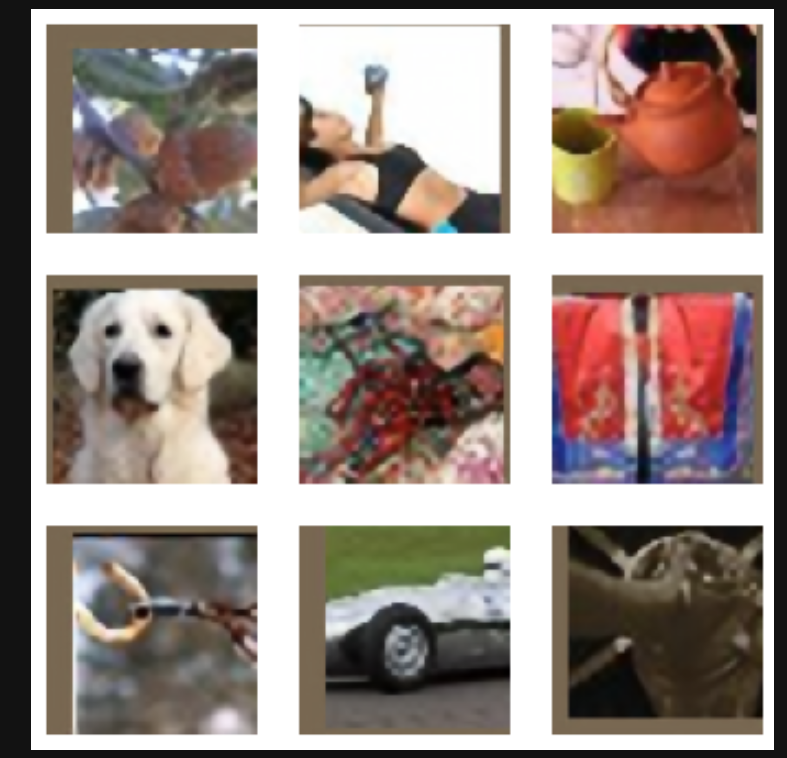

In [41]:
# show_images(denorm(t[:9]), imsize=2)

# Perceptual loss

In [42]:
cmodel = torch.load('/kaggle/input/models/seif222/classifier-for-unet/pytorch/default/1/classifier_for_Unet.pkl',weights_only=False,map_location='cuda')

In [43]:
xb,yb = next(iter(dls.valid))
with torch.autocast('cuda'), torch.no_grad(): preds = to_cpu(cmodel(yb.cuda().half()))
preds.shape

torch.Size([1024, 200])

`autocast()` and `.half()` are for mixed percision

In [44]:
id2str = (path/'wnids.txt').read_text().splitlines()
all_synsets = [o.split('\t') for o in (path/'words.txt').read_text().splitlines()]
synsets = {k:v.split(',', maxsplit=1)[0] for k,v in all_synsets if k in id2str}

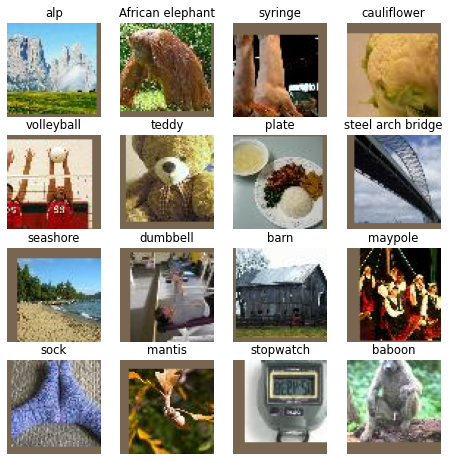

In [45]:
# see the model preds
titles = [synsets[id2str[o]] for o in preds.argmax(dim=1)]
show_images(denorm(yb[:16]), imsize=2, titles=titles[:16])

In [46]:
cmodel

Sequential(
  (0): ResBlock(
    (convs): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): GeneralRelu()
      )
      (1): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (idconv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
    )
    (act): GeneralRelu()
  )
  (1): ResBlock(
    (convs): Sequential(
      (0): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): GeneralRelu()
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (1): 

In [47]:
# let's use the first 4 layers to get features
for i in range(4,len(cmodel)): del(cmodel[4])

In [48]:
cmodel

Sequential(
  (0): ResBlock(
    (convs): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): GeneralRelu()
      )
      (1): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (idconv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
    )
    (act): GeneralRelu()
  )
  (1): ResBlock(
    (convs): Sequential(
      (0): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): GeneralRelu()
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (1): 

In [49]:
# try getting the features for the original_images and preds_images
# with torch.autocast('cuda'),torch.no_grad():
#   feats = to_cpu(cmodel(yb.cuda())).float()
#   preds = to_cpu(learn.model(yb.cuda())).float()
#   preds_feats = to_cpu(cmodel(preds.cuda())).float()

# feats.shape, preds_feats.shape

In [50]:
yb.shape

torch.Size([1024, 3, 64, 64])

In [51]:
def comb_loss(preds,targs):
  with torch.autocast('cuda'):
    with torch.no_grad(): feats = cmodel(targs).float()
    preds_feats = cmodel(preds).float()
  return F.mse_loss(preds,targs)+F.mse_loss(feats,preds_feats)/10

- why the `/10`? -> we ran few epochs and found out that scaling difference was `*10`
- `with torch.no_grad(): feats = cmodel(targs).float()`-> no need to track grads here (it is not using for model learning, just for the comparison)


In [52]:
def get_unet():
    model = TinyUnet()
    last_res = model.up[-1]
    zero_weights(last_res.convs[-1][-1])
    zero_weights(last_res.idconv[0])
    zero_weights(model.end.convs[-1][-1])
    return model

<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="31"></progress> 15.82% [31/196 00:27&lt;02:26... 0.369]</div></div>

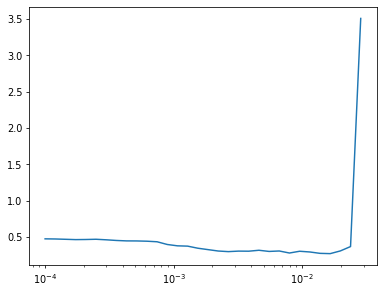

In [53]:
Learner(get_unet(), dls, comb_loss, cbs=lr_cbs, opt_func=opt_func).lr_find(start_lr=1e-4, gamma=1.2)

In [54]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(get_unet(), dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [55]:
# learn.fit(epochs)

    loss	epoch	train
    0.190	0	train
    0.105	0	eval
    0.128	1	train
    0.097	1	eval
    0.116	2	train
    0.094	2	eval
    0.111	3	train
    0.092	3	eval
    0.108	4	train
    0.091	4	eval
    0.106	5	train
    0.090	5	eval
    0.104	6	train
    0.089	6	eval
    0.103	7	train
    0.089	7	eval
    0.102	8	train
    0.088	8	eval
    0.101	9	train
    0.087	9	eval
    0.101	10	train
    0.086	10	eval
    0.100	11	train
    0.086	11	eval
    0.099	12	train
    0.086	12	eval
    0.099	13	train
    0.085	13	eval
    0.099	14	train
    0.085	14	eval
    0.098	15	train
    0.085	15	eval
    0.098	16	train
    0.084	16	eval
    0.098	17	train
    0.084	17	eval
    0.097	18	train
    0.084	18	eval
    0.097	19	train
    0.084	19	eval


Can't compare the loss with previous models becuase it is not the same loss

In [56]:
# p,t,inp = learn.capture_preds(inps=True)

In [57]:
# show_images(denorm(inp[:9]), imsize=2)

In [58]:
# show_images(denorm(p[:9]), imsize=2)

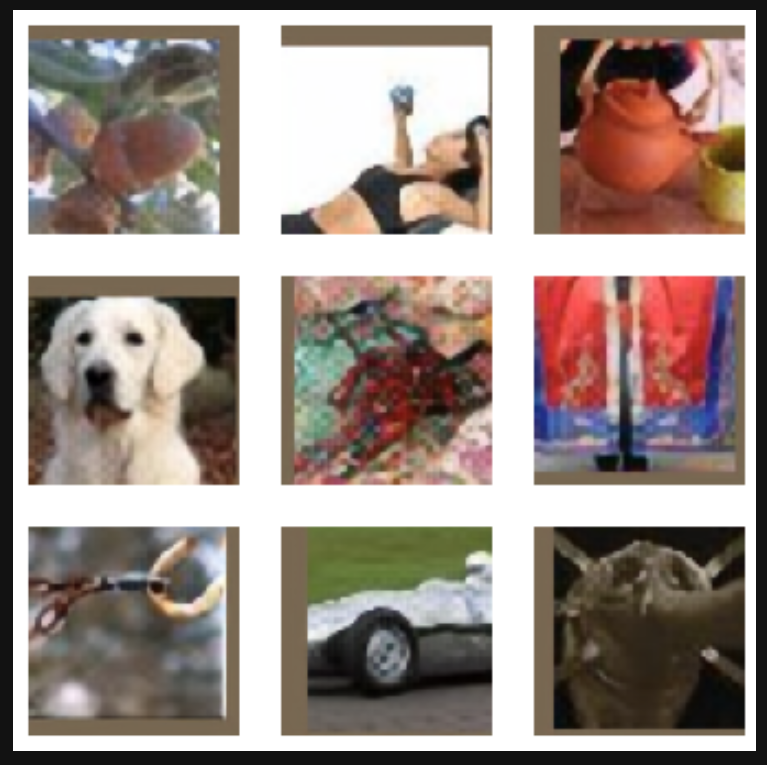

In [59]:
# show_images(denorm(t[:9]), imsize=2)

# PreTrained Classifier layers as Down_sampling layers(+weights)

## Make a GPU Batch Transform 
- Make the second transformation that happen to data (killing details (64->32->64), random erase) on the GPU  to prevent the CPU bottleneck
- The problem is that it doesn't make a different tfms to each image in the batch it amkes the same for all batch images, but we sacrifice this for some more speed

In [60]:
class DegradeCB(Callback):
    order = DeviceCB.order + 1  # data already on GPU
    def before_batch(self, learn):
        yb = learn.batch[0]          # clean images (stage 1 already done)
        xb = TF.resize(yb, [32,32])       # shrink — on GPU, whole batch at once
        xb = F.interpolate(xb, size=[64,64], mode='nearest')  # stretch back (same as the one before but just more specific syntax)
        xb = rand_erase(xb)            
        learn.batch = (xb, yb)

- `F.interpolate` and `TF.resize` operate on whatever `tensor.device` the input is on.
-  `rand_erase` -> generate randoms on CPU, but real work is on the GPU.

In [61]:
class TinyDS_GPU:
    def __init__(self, path):
        self.path = Path(path)
        self.files = glob(str(path/'**/*.JPEG'), recursive=True)
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = read_image(self.files[i], mode=ImageReadMode.RGB)/255
        tfms_img = tfms((img-xmean[:,None,None])/xstd[:,None,None])
        return tfms_img, tfms_img 


In [62]:
# CPU
tds = TinyDS(path/'train')
vds = TinyDS(path/'val')

tfm_tds = TfmDS(tds, tfmx)
tfm_vds = TfmDS(vds, partial(tfmx, erase=False))
dls_cpu = DataLoaders(*get_dls(tfm_tds, tfm_vds, bs=bs, num_workers=4))

# GPU
tds_GPU = TinyDS_GPU(path/'train')
vds_GPU = TinyDS_GPU(path/'val')
dls = DataLoaders(*get_dls(tds_GPU, vds_GPU, bs=bs, num_workers=4)) # MAKE num workers 4 on kaggle
cbs += [DegradeCB()] # Add the CB

## Model Training

In [63]:
model = get_unet()

In [64]:
pmodel = torch.load('/kaggle/input/models/seif222/classifier-for-unet/pytorch/default/1/classifier_for_Unet.pkl',weights_only=False)
model.start.load_state_dict(pmodel[0].state_dict()) # 1st ResNet
for i in range(5): model.dn[i].load_state_dict(pmodel[i+1].state_dict()) # other layers

In [65]:
for p in model.dn.parameters(): p.requires_grad_(False)

Because we have to train the other weights in the unet (as up_sampling, etc) so that it start to become something other than random numbers, for like at least one epoch

In [66]:
# split the model on 2 kaggle gpus
model = nn.DataParallel(model)

In [67]:
epochs = 1
lr = 3e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [68]:
# learn.fit(epochs)

In [69]:
# show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

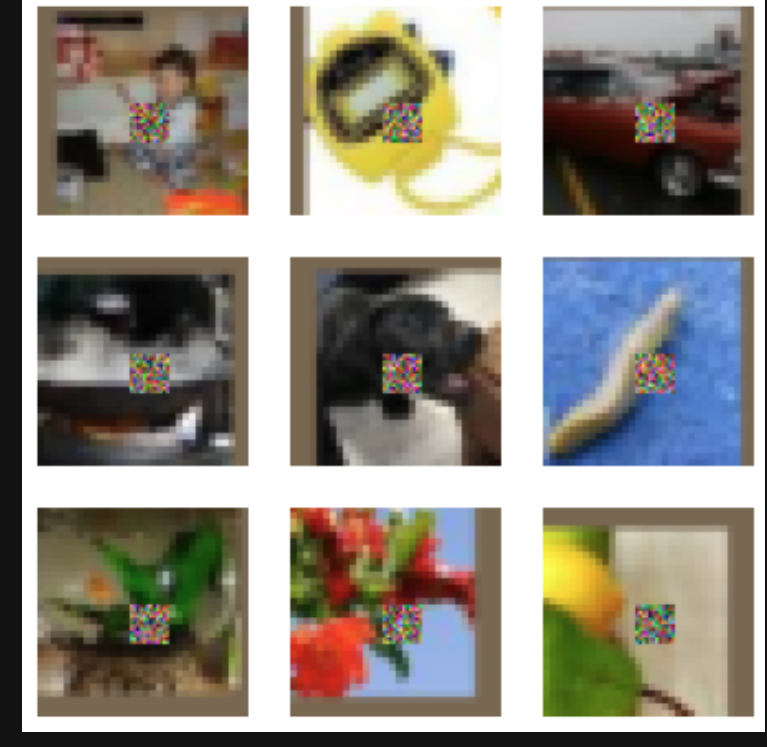

In [70]:
model = model.module  # get it back on one device (cuda'0')

In [71]:
next(model.parameters()).device

device(type='cpu')

In [72]:
for o in model.dn.parameters(): o.requires_grad_(True)

In [73]:
model = nn.DataParallel(model) # Rewrap it

In [74]:
epochs = 20
lr = 3e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [75]:
# learn.fit(epochs)

    loss	epoch	train
    0.194	0	train
    0.196	0	eval
    0.183	1	train
    0.172	1	eval
    0.178	2	train
    0.178	2	eval
    0.169	3	train
    0.163	3	eval
    0.162	4	train
    0.154	4	eval
    0.161	5	train
    0.152	5	eval
    0.156	6	train
    0.147	6	eval
    0.155	7	train
    0.155	7	eval
    0.153	8	train
    0.174	8	eval
    0.149	9	train
    0.148	9	eval
    0.148	10	train
    0.146	10	eval
    0.148	11	train
    0.146	11	eval
    0.147	12	train
    0.149	12	eval
    0.147	13	train
    0.152	13	eval
    0.145	14	train
    0.149	14	eval
    0.147	15	train
    0.148	15	eval
    0.144	16	train
    0.136	16	eval
    0.144	17	train
    0.143	17	eval
    0.143	18	train
    0.144	18	eval
    0.142	19	train
    0.144	19	eval


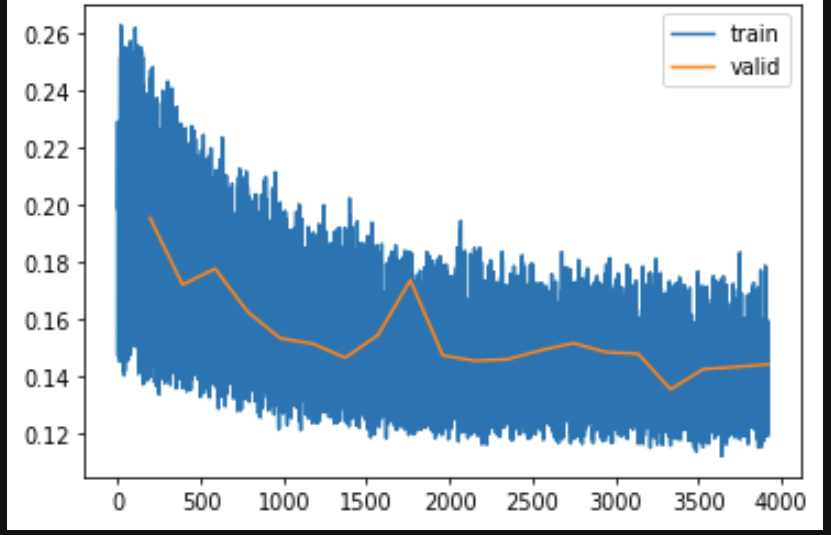

The applying of the same random erase on all batch made the training instable, loss going down, but each batch model is fighting noisy gradients.
- CPU tfms is better, so that each image in batch gets it's own diff rand_erase, but we sacrifice that for the Speed

In [76]:
# torch.save(learn.model, '/kaggle/working/superres-closs-pclass.pkl')

In [77]:
# p,t,inp = learn.capture_preds(inps=True)

In [78]:
# show_images(denorm(inp[:9]), imsize=2)

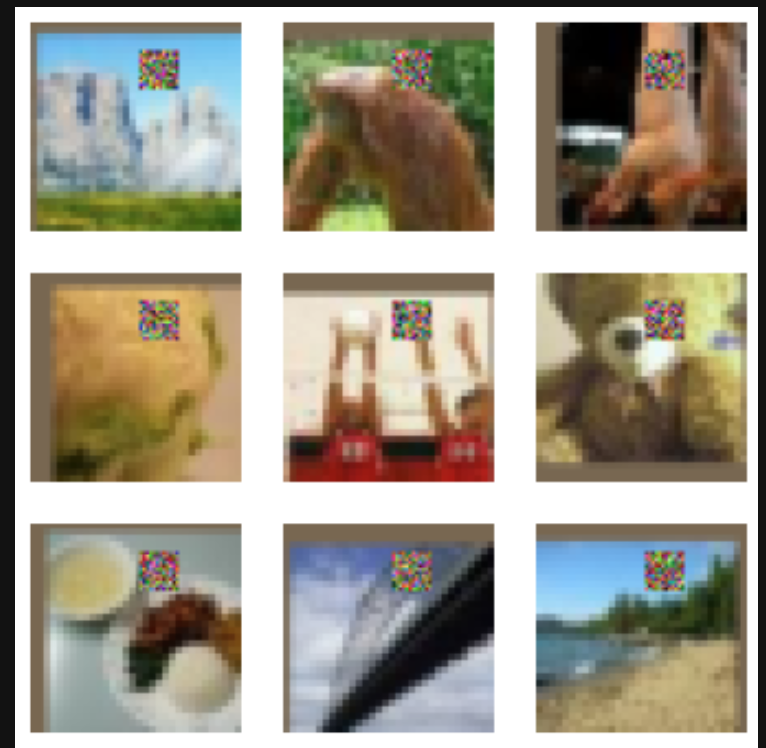

In [79]:
# show_images(denorm(p[:9]), imsize=2)

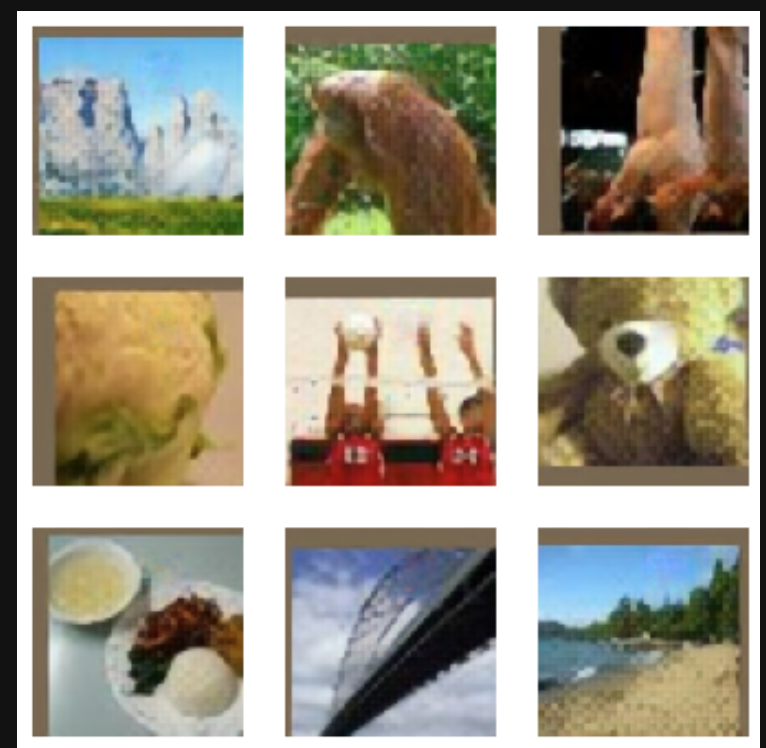

In [80]:
# show_images(denorm(t[:9]), imsize=2)

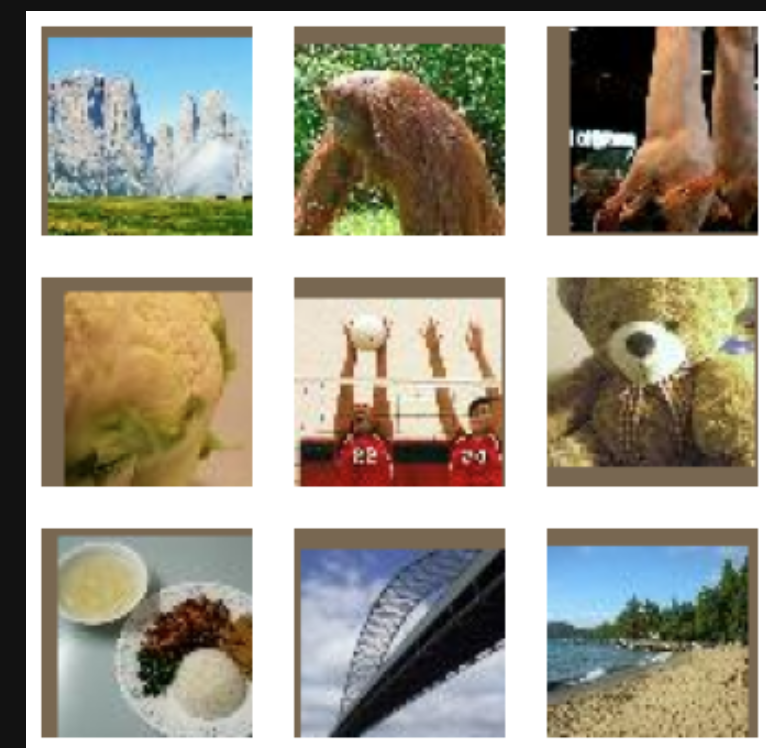

# Cross Convs
- Idea is instead of adding the `down_sampling` part to the equivelant `up_sampling` one directly during the `up_sampling`, we pass the `down_sampling` part in `cross_conv` first, then add it to `up_sampling`

## Using the CPU_transform (each element in batch gets it's own unique transform)

In [81]:
def cross_conv(nf, act, norm):
  return nn.Sequential(
      ResBlock(nf, nf, act=act, norm=norm),
      nn.Conv2d(nf, nf, kernel_size=3, padding=1)
  )

both `ResBlock` and the `Conv2d` here use `ks=3`, `padding=1`, `stride=1` → `same spatial size in`, `same spatial size out`. ✓

In [82]:
class TinyUnet(nn.Module):
  def __init__(self, act=act_gr, nfs=(32,64,128,256,512,1024), norm=nn.BatchNorm2d):
    super().__init__()
    self.start = ResBlock(3, nfs[0], stride=1, act=act, norm=norm)
    self.dn = nn.ModuleList([ResBlock(nfs[i], nfs[i+1], stride=2, act=act, norm=norm) for i in range(len(nfs)-1)])
    self.cc = nn.ModuleList([cross_conv(nfs[i], act=act, norm=norm) for i in reversed(range(len(nfs)))]) # <- Added
    self.up = nn.ModuleList([up_block(nfs[i], nfs[i-1], act=act, norm=norm) for i in reversed(range(1,len(nfs)))])
    self.up += [ResBlock(nfs[0], 3, stride=1, act=act, norm=norm)]
    self.end =  ResBlock(3, 3, act=nn.Identity, norm=norm)

  def forward(self, x):
    layers = [x]
    x = self.start(x)
    for l in self.dn:
      layers.append(x)
      x = l(x)
    n = len(layers)
    for i,l in enumerate(self.up):
      if i!=0: x += self.cc[i](layers[n-i]) # <- Added
      x = l(x)
    return  self.end(x+layers[0])

In [124]:
cbs.pop()
cbs

we are going to use the CPU dls, so that we can see the best result we can get

In [125]:
model = get_unet()

In [126]:
pmodel = torch.load('/kaggle/input/models/seif222/classifier-for-unet/pytorch/default/1/classifier_for_Unet.pkl',weights_only=False, map_location='cuda')
model.start.load_state_dict(pmodel[0].state_dict())
for i in range(5): model.dn[i].load_state_dict(pmodel[i+1].state_dict())

In [127]:
for p in model.dn.parameters(): p.requires_grad_(False)

In [135]:
# See the batchs that model gets
lr = 3e-3
one_batch_cbs = [DeviceCB(), MixedPrecision(), SingleBatchCB()]
learn = Learner(model, dls_cpu, comb_loss, lr=lr, cbs=one_batch_cbs, opt_func=opt_func)
learn.fit(1)

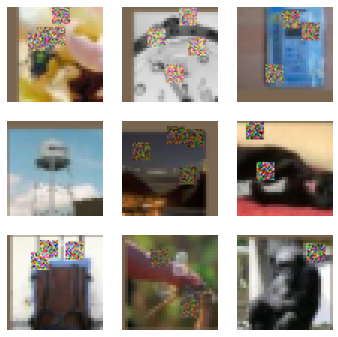

In [137]:
show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

In [ ]:
epochs = 1
lr = 3e-3
tmax = epochs * len(dls_cpu.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls_cpu, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

loss,epoch,train
0.352,0,train
0.206,0,eval


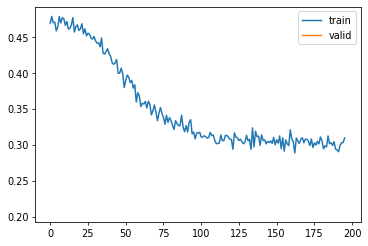

In [129]:
learn.fit(epochs)

In [131]:
for o in model.dn.parameters(): o.requires_grad_(True)

In [132]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls_cpu.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls_cpu, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [ ]:
# learn.fit(epochs)

forgot to put model on 2 GPUs

    loss	epoch	train
    0.297	0	train
    0.196	0	eval
    0.290	1	train
    0.187	1	eval
    0.281	2	train
    0.182	2	eval
    0.270	3	train
    0.179	3	eval
    0.259	4	train
    0.177	4	eval
    0.254	5	train
    0.176	5	eval
    0.252	6	train
    0.176	6	eval
    0.248	7	train
    0.176	7	eval
    0.246	8	train
    0.175	8	eval
    0.245	9	train
    0.175	9	eval
    0.244	10	train
    0.175	10	eval
    0.243	11	train
    0.175	11	eval
    0.243	12	train
    0.174	12	eval
    0.243	13	train
    0.174	13	eval
    0.242	14	train
    0.174	14	eval
    0.243	15	train
    0.174	15	eval
    0.242	16	train
    0.174	16	eval
    0.242	17	train
    0.174	17	eval
    0.242	18	train
    0.174	18	eval
    0.242	19	train
    0.174	19	eval


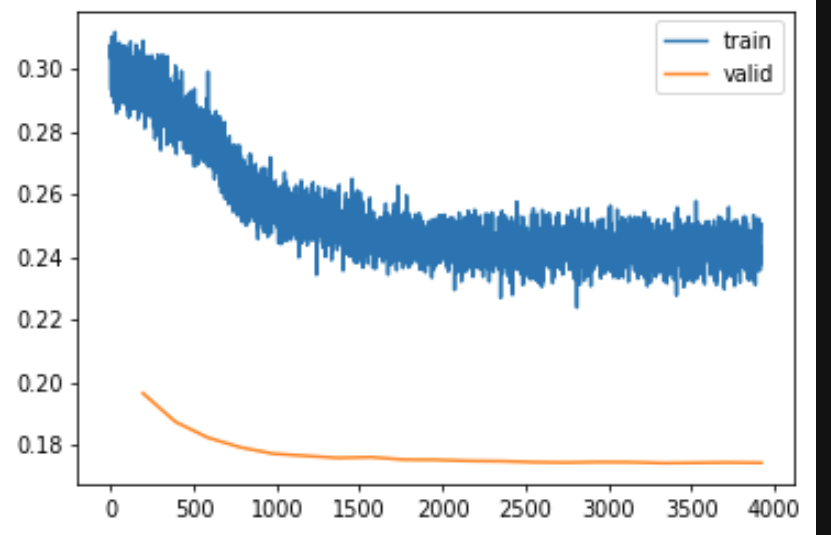

In [ ]:
# p,t,inp = learn.capture_preds(inps=True)

In [ ]:
# show_images(denorm(inp[:9]), imsize=2)

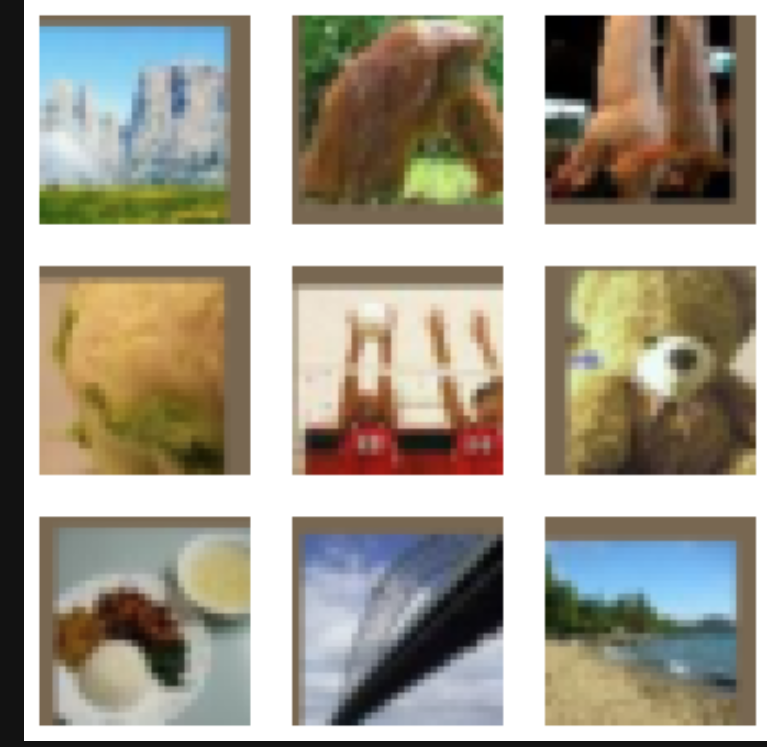

In [ ]:
# show_images(denorm(p[:9]), imsize=2)

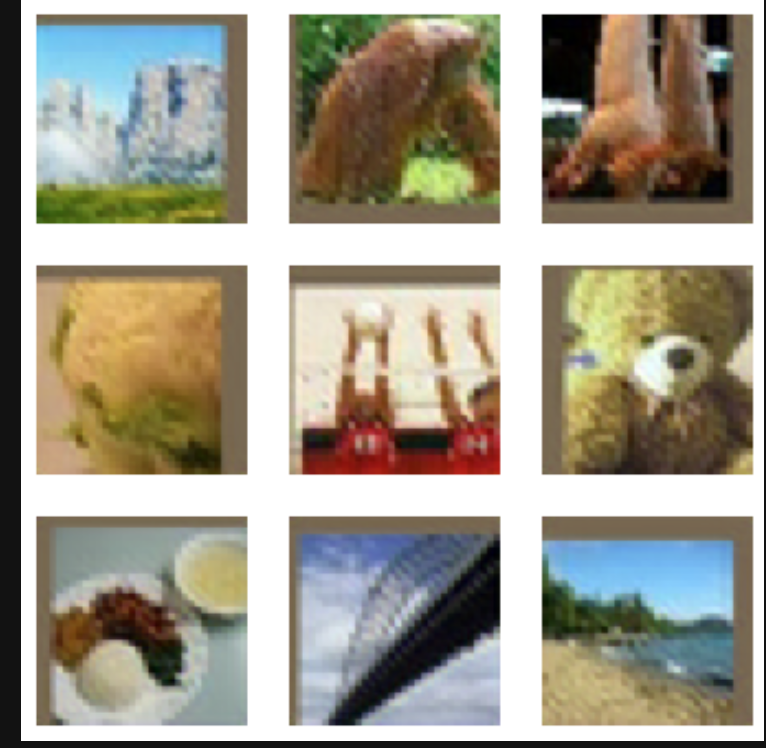

In [ ]:
# show_images(denorm(t[:9]), imsize=2)

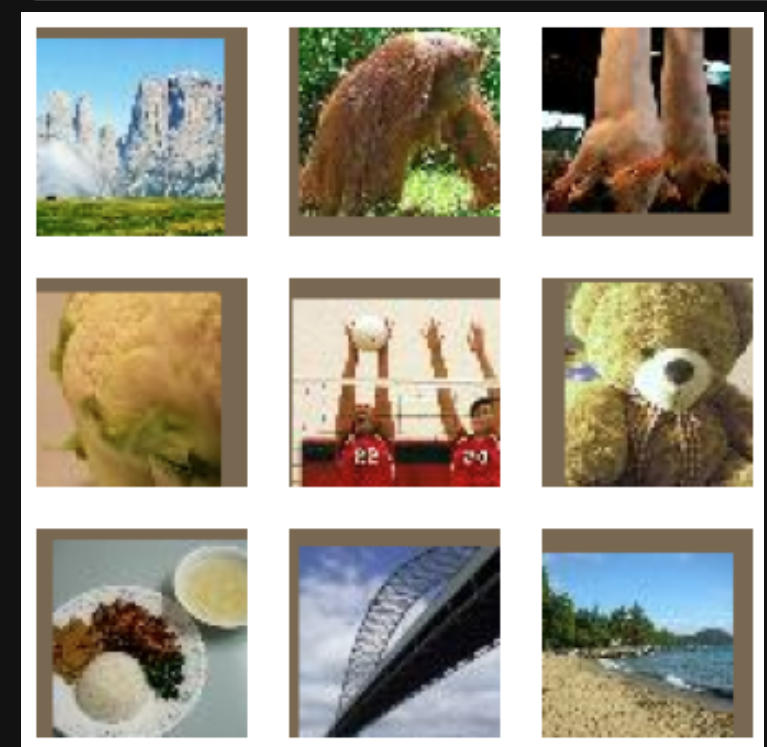

In [92]:
# torch.save(learn.model, '/kaggle/working/superres-cross-closs-pclass.pkl')

## Try using the GPU_transform (all batch same transform)

In [138]:
cbs += [DegradeCB()] # Add the CB

In [150]:
cbs

In [151]:
model = get_unet()

In [152]:
pmodel = torch.load('/kaggle/input/models/seif222/classifier-for-unet/pytorch/default/1/classifier_for_Unet.pkl',weights_only=False, map_location='cuda')
model.start.load_state_dict(pmodel[0].state_dict())
for i in range(5): model.dn[i].load_state_dict(pmodel[i+1].state_dict())

In [153]:
for p in model.dn.parameters(): p.requires_grad_(False)

In [154]:
model = nn.DataParallel(model)

In [155]:
epochs = 1
lr = 3e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

loss,epoch,train
0.247,0,train
0.173,0,eval


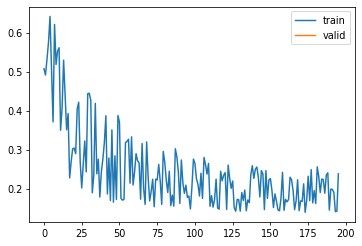

In [156]:
learn.fit(epochs)

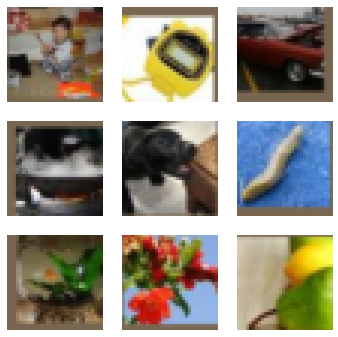

In [157]:
show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

This batch didn't have aug, so let's see one using SingleBatchCB

In [166]:
one_batch_cbs = [DeviceCB(), MixedPrecision(), SingleBatchCB(), DegradeCB()]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=one_batch_cbs, opt_func=opt_func)
learn.fit(1)

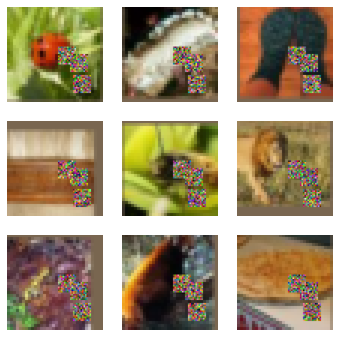

In [167]:
show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

In [168]:
model = model.module  # get it back on one device (cuda'0')

In [169]:
for o in model.dn.parameters(): o.requires_grad_(True)

In [170]:
model = nn.DataParallel(model)

In [171]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

loss,epoch,train
0.274,0,train
0.196,0,eval
0.185,1,train
0.178,1,eval
0.167,2,train
0.161,2,eval
0.161,3,train
0.172,3,eval
0.161,4,train
0.149,4,eval


/kaggle/working/course22p2/miniai/sgd.py:20: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if learn.training: self.schedo.step()


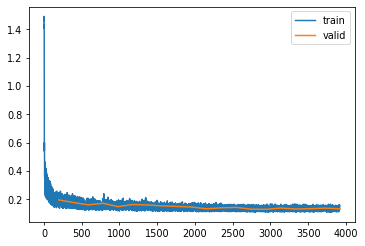

In [172]:
learn.fit(epochs)

loss,epoch,train
0.131,0,eval


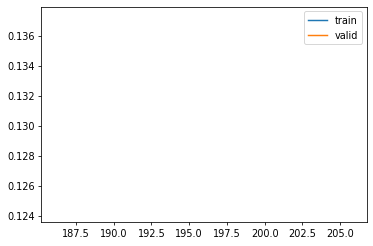

In [173]:
p,t,inp = learn.capture_preds(inps=True)

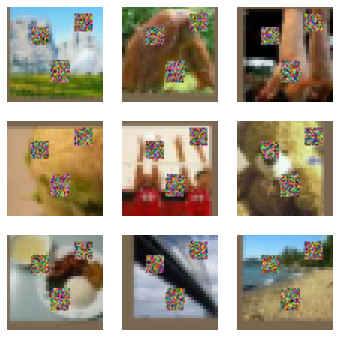

In [174]:
show_images(denorm(inp[:9]), imsize=2)

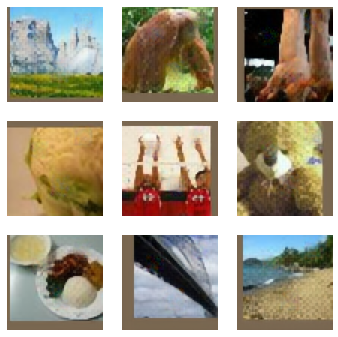

In [175]:
show_images(denorm(p[:9]), imsize=2)

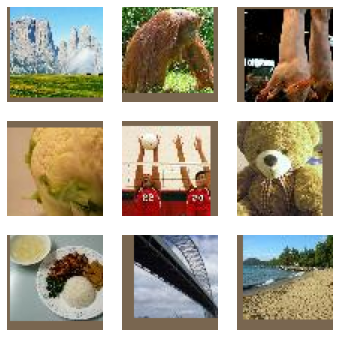

In [176]:
show_images(denorm(t[:9]), imsize=2)

In [177]:
torch.save(learn.model, '/kaggle/working/supperres-cross-closs-pclass-GPU_BATCH.pkl')

# Colorizing Images Unet

In [235]:
def tfmx(x,erase=True):
  x = TF.rgb_to_grayscale(x)
  x = x.repeat(3,1,1)
  if erase: x = rand_erase(x)
  return x

In [236]:
class DegradeCB(Callback):
    order = DeviceCB.order + 1  # data already on GPU
    def before_batch(self, learn):
        yb = learn.batch[0]          
        xb = TF.rgb_to_grayscale(yb)
        xb = xb.repeat(1,3,1,1) 
        xb = rand_erase(xb)
        learn.batch = (xb, yb)

In [216]:
# cbs.pop() #pop the old DegradeCB

In [238]:
cbs

In [237]:
# CPU
tds = TinyDS(path/'train')
vds = TinyDS(path/'val')

tfm_tds = TfmDS(tds, tfmx)
tfm_vds = TfmDS(vds, partial(tfmx, erase=False))
dls_cpu = DataLoaders(*get_dls(tfm_tds, tfm_vds, bs=bs, num_workers=4))


# GPU
tds_GPU = TinyDS_GPU(path/'train')
vds_GPU = TinyDS_GPU(path/'val')
dls = DataLoaders(*get_dls(tds_GPU, vds_GPU, bs=bs, num_workers=4)) # MAKE num workers 4 on kaggle
# cbs += [DegradeCB()] # Add the CB

In [239]:
model = get_unet()

In [240]:
pmodel = torch.load('/kaggle/input/models/seif222/classifier-for-unet/pytorch/default/1/classifier_for_Unet.pkl',weights_only=False, map_location='cuda')
model.start.load_state_dict(pmodel[0].state_dict())
for i in range(5): model.dn[i].load_state_dict(pmodel[i+1].state_dict())

In [241]:
for p in model.dn.parameters(): p.requires_grad_(False)

In [242]:
model = nn.DataParallel(model)

loss,epoch,train
0.249,0,train
0.167,0,eval


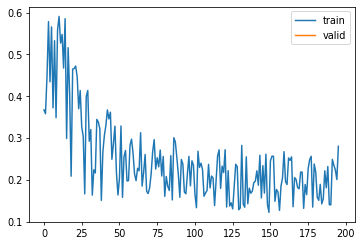

In [243]:
epochs = 1
lr = 3e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)
learn.fit(epochs)

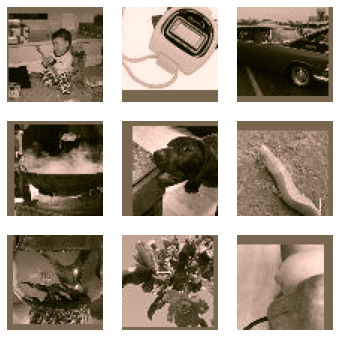

In [244]:
show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

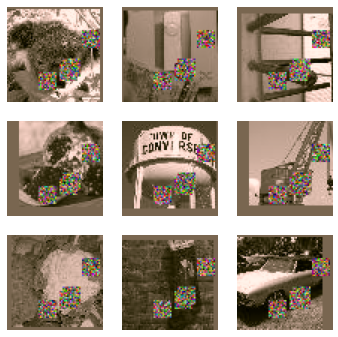

In [211]:
# one_batch_cbs = [DeviceCB(), MixedPrecision(), SingleBatchCB(), DegradeCB()]
# learn = Learner(model, dls, comb_loss, lr=lr, cbs=one_batch_cbs, opt_func=opt_func)
# learn.fit(1)
# show_images(denorm(to_cpu(learn.batch[0][:9])), imsize=2)

In [245]:
model = model.module  # get it back on one device (cuda'0')

In [246]:
for o in model.dn.parameters(): o.requires_grad_(True)

In [247]:
model = nn.DataParallel(model)

loss,epoch,train
0.181,0,train
0.170,0,eval
0.179,1,train
0.186,1,eval
0.174,2,train
0.181,2,eval
0.176,3,train
0.173,3,eval
0.172,4,train
0.223,4,eval


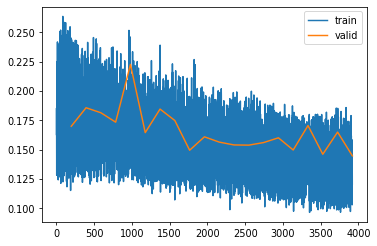

In [248]:
epochs = 20
lr = 5e-3
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(model, dls, comb_loss, lr=lr, cbs=cbs+xtra, opt_func=opt_func)
learn.fit(epochs)

loss,epoch,train
0.151,0,eval


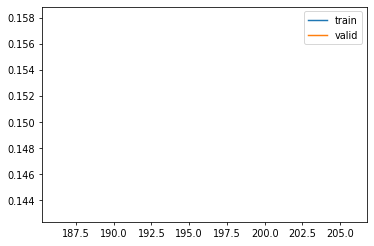

In [249]:
p,t,inp = learn.capture_preds(inps=True)

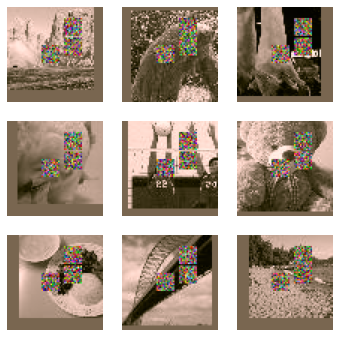

In [250]:
show_images(denorm(inp[:9]), imsize=2)

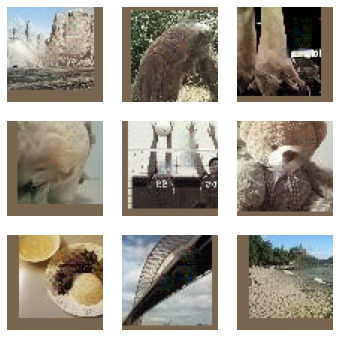

In [251]:
show_images(denorm(p[:9]), imsize=2)

- We can make the colors more saturated using LAB (LAB separates brightness from color (brightness(L),COLOR1(A),COLOR2(B)),instead of RGB, but it will take time to implement with not much learning
- L1(absolute error) [MAE] beats MSE for colorization), Because MSE amplifies outliers, so in some way it makes the model afraid to go to more extreme (saturated colors) 

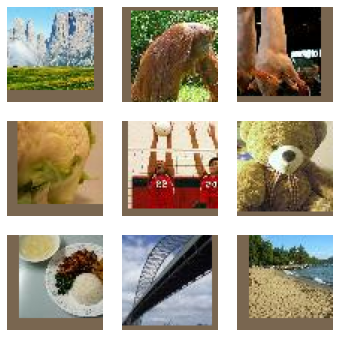

In [252]:
show_images(denorm(t[:9]), imsize=2)